# Dimensionality Reduction & Unsupervised Clustering on the UCI Wine Dataset

**Author**: Mohan Asanthibattula  
**Project**: `pca-clustering-wine`  
**License**: MIT (Code) / CC BY 4.0 (Dataset)  
**Execution Environment**: Python 3.12.8 (Scikit-Learn, SciPy, Pandas, NumPy, Matplotlib, Seaborn, Plotly)

---

## 1. Scientific Background & Dataset Provenance
The **Wine Recognition Dataset** is a classic multivariate benchmark originally collected by **M. Forina et al. (1991)** at the *Institute of Pharmaceutical and Food Analysis and Technologies, Genoa, Italy*, and hosted by the **UCI Machine Learning Repository** (licensed under **CC BY 4.0**). It comprises chemical analyses of **178 wine samples** derived from three distinct grape cultivars grown in the Piedmont region of Italy.

Each observation records **13 continuous physicochemical attributes**:
1. `alcohol`: Ethanol concentration (% vol)
2. `malic_acid`: Malic acid content (g/L)
3. `ash`: Total mineral ash content (g/L)
4. `alcalinity_of_ash`: Ash alkalinity (mEq/L)
5. `magnesium`: Magnesium concentration (mg/L)
6. `total_phenols`: Total phenolic compounds (absorbance units / g/L)
7. `flavanoids`: Flavanoid polyphenol content (g/L)
8. `nonflavanoid_phenols`: Non-flavanoid polyphenol content (g/L)
9. `proanthocyanins`: Proanthocyanin tannins (g/L)
10. `color_intensity`: Color intensity (absorbance at 420 nm + 520 nm)
11. `hue`: Ratio of absorbance at 420 nm / 520 nm
12. `od280/od315_of_diluted_wines`: Protein / nucleic acid / phenol absorbance ratio
13. `proline`: Proline amino acid concentration (mg/L)

An additional discrete column, `cultivar` (classes 0, 1, 2 with sample counts 59, 71, and 48), records the true botanical grape cultivar.

> **CRITICAL UNSUPERVISED INVARIANT**: In rigorous unsupervised learning, target labels must NEVER be used during preprocessing, scaling, dimensionality reduction, or cluster formation. The `cultivar` column is strictly isolated and introduced only in Section 7 as an external post-hoc benchmark to measure the Adjusted Rand Index (ARI) and evaluate unsupervised concordance.

---

## 2. Research Objectives
1. **Explore Feature Scale Disparities**: Demonstrate why standardization is mathematically mandatory before distance-based unsupervised learning.
2. **Dimensionality Reduction via PCA**: Compute eigenvalues, explained variance ratios, scree plot inflection points, and Kaiser criterion to identify intrinsic dimensionality and driver chemical loadings.
3. **Partition-Based Clustering (K-Means)**: Tune $k \in [2, 10]$ using inertia elbow analysis and silhouette score profiling; validate sample-level silhouette distributions.
4. **Comparative Clustering (Hierarchical & DBSCAN)**: Construct Ward linkage dendrogram and examine density-based clustering behavior across $k$-distance neighborhood scales.
5. **Multi-Dimensional Cluster Visualization**: Project clusters into 2D and 3D principal component subspaces with centroids and interactive Plotly visualization.
6. **Ground-Truth Validation**: Quantify botanical alignment via Adjusted Rand Index (ARI) and contingency cross-tabulation.

---

## 3. Workflow Roadmap

| Section | Phase | Primary Algorithms / Techniques | Key Outputs & Diagnostics |
|---|---|---|---|
| **0** | Problem Formulation | Theoretical framework & provenance | Scope, dataset attributes, roadmap |
| **1** | Ingestion & Scale Inspection | Pandas summary, distribution ranges | Feature scale boxplot (`01_feature_scales.png`) |
| **2** | Feature Standardization | `StandardScaler` (Z-score normalization) | Mean $\approx 0$, std $= 1$ invariant proofs |
| **3** | Principal Component Analysis | Orthogonal eigendecomposition | Scree plot, Kaiser rule, Loadings heatmap (`02`, `03`) |
| **4** | K-Means Clustering | Inertia & Silhouette optimization ($k=2..10$) | Elbow curve, silhouette diagram (`04`, `05`) |
| **5** | Hierarchical & DBSCAN | Ward linkage dendrogram, $k$-distance | Dendrogram, $k$-dist plot, comparison table (`06`, `07`) |
| **6** | 2D / 3D Cluster Projections | PCA coordinate projections, Plotly 3D | 2D/3D scatter plots (`08`, `3d_cluster_projection.html`) |
| **7** | Ground-Truth Cultivar Concordance | Adjusted Rand Index (ARI), Contingency matrix | Cultivar comparison scatter (`09_clusters_vs_cultivars.png`) |
| **8** | Synthesis & Conclusions | Chemometric profile interpretation | Key chemical drivers & final synthesis |


---
## Section 1: Ingestion & Feature Scale Inspection

### Methodology & Pre-Analysis Rationale
Unsupervised distance metrics (e.g., Euclidean distance in K-Means and Hierarchical clustering) compute distances as:
$$d(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_{j=1}^{p} (u_j - v_j)^2}$$

If feature scales differ by orders of magnitude, features with high variances (such as `proline` ranging from 278 to 1680 mg/L) will numerically dominate features with small variances (such as `nonflavanoid_phenols` ranging from 0.13 to 0.66). Below, we load the raw dataset, verify its integrity, and plot the raw feature ranges to quantify this disparity.


Dataset successfully loaded.
Shape: 178 samples, 14 columns (13 physicochemical features + 1 cultivar target)
Missing values across entire dataset: 0
Data types: All features are continuous floats/integers ([dtype('float64')])
Target distribution (cultivars):
cultivar
0    59
1    71
2    48
Name: count, dtype: int64

--- Feature Scale Summary Statistics ---
                                mean     std     min     50%      max    range  variance
alcohol                        13.00    0.81   11.03   13.05    14.83     3.80      0.66
malic_acid                      2.34    1.12    0.74    1.87     5.80     5.06      1.25
ash                             2.37    0.27    1.36    2.36     3.23     1.87      0.08
alcalinity_of_ash              19.49    3.34   10.60   19.50    30.00    19.40     11.15
magnesium                      99.74   14.28   70.00   98.00   162.00    92.00    203.99
total_phenols                   2.30    0.63    0.98    2.36     3.88     2.90      0.39
flavanoids      

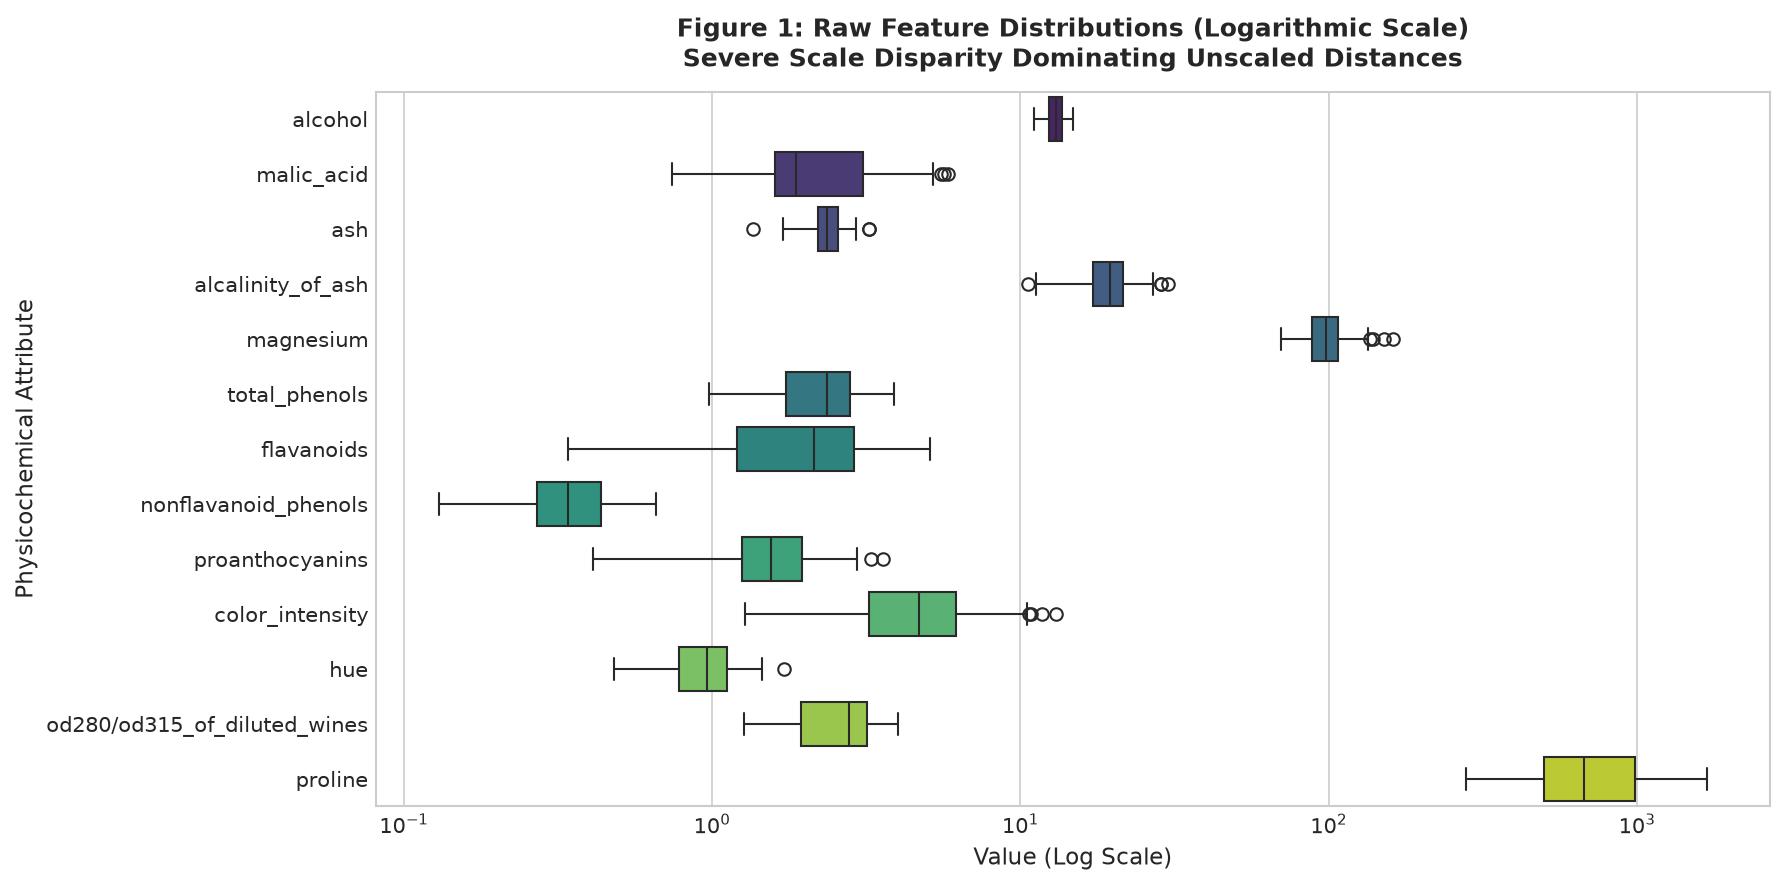

Scale Imbalance Ratio: proline variance (99166.72) is 6,402,547.7x larger than nonflavanoid_phenols variance (0.015489)!


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
os.makedirs('../reports/figures', exist_ok=True)
os.makedirs('../reports/proof', exist_ok=True)

# Load data
df = pd.read_csv('../data/wine.csv')
features = [col for col in df.columns if col != 'cultivar']
X_raw = df[features].copy()
cultivars = df['cultivar'].copy()

print(f"Dataset successfully loaded.")
print(f"Shape: {df.shape[0]} samples, {df.shape[1]} columns ({len(features)} physicochemical features + 1 cultivar target)")
print(f"Missing values across entire dataset: {df.isnull().sum().sum()}")
print(f"Data types: All features are continuous floats/integers ({df[features].dtypes.unique()})")
print(f"Target distribution (cultivars):\n{cultivars.value_counts().sort_index()}")

# Summary statistics table
summary_stats = X_raw.describe().T[['mean', 'std', 'min', '50%', 'max']]
summary_stats['range'] = summary_stats['max'] - summary_stats['min']
summary_stats['variance'] = summary_stats['std'] ** 2
print("\n--- Feature Scale Summary Statistics ---")
print(summary_stats.round(2).to_string())

# Figure 1: Raw feature scale comparison
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=X_raw, orient='h', palette='viridis', ax=ax)
ax.set_xscale('log')
ax.set_title("Figure 1: Raw Feature Distributions (Logarithmic Scale)\nSevere Scale Disparity Dominating Unscaled Distances", fontsize=12, pad=12, fontweight='bold')
ax.set_xlabel("Value (Log Scale)", fontsize=11)
ax.set_ylabel("Physicochemical Attribute", fontsize=11)
plt.tight_layout()
plt.savefig('../reports/figures/01_feature_scales.png', dpi=150, bbox_inches='tight')
plt.show()

max_var_feat = summary_stats['variance'].idxmax()
min_var_feat = summary_stats['variance'].idxmin()
var_ratio = summary_stats.loc[max_var_feat, 'variance'] / summary_stats.loc[min_var_feat, 'variance']
print(f"Scale Imbalance Ratio: {max_var_feat} variance ({summary_stats.loc[max_var_feat, 'variance']:.2f}) is {var_ratio:,.1f}x larger than {min_var_feat} variance ({summary_stats.loc[min_var_feat, 'variance']:.6f})!")


### Diagnostic Finding: Scale Disparity
The statistical summary and Figure 1 demonstrate an extreme scale disparity:
- `proline` displays a variance exceeding $99,000$ (range: 278 to 1680), whereas `nonflavanoid_phenols` has a variance of merely $0.015$ (range: 0.13 to 0.66).
- The variance ratio exceeds **6,400,000:1**. 
- Without standardization, any unweighted Euclidean distance calculation would reflect almost solely variations in `proline` and `magnesium`, completely ignoring critical chemical signals like `flavanoids`, `alcohol`, and `od280/od315`.


---
## Section 2: Feature Standardization via `StandardScaler`

### Methodology
To ensure equal weight across all 13 physicochemical dimensions, we apply Z-score standardization:
$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$
where $\mu_j$ is the empirical feature mean and $\sigma_j$ is the sample standard deviation.

Following transformation, every standardized feature $z_j$ will possess zero empirical mean ($\mathbb{E}[z_j] = 0$) and unit variance ($\text{Var}(z_j) = 1.0$), eliminating measurement unit bias while preserving the correlation structure.


In [2]:
from sklearn.preprocessing import StandardScaler

# Fit scaler strictly on feature matrix (cultivar completely omitted)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
df_scaled = pd.DataFrame(X_scaled, columns=features)

# Verification diagnostics
scaled_means = df_scaled.mean()
scaled_stds = df_scaled.std(ddof=0) # population std for StandardScaler

scaled_audit = pd.DataFrame({
    'Feature': features,
    'Scaled Mean': scaled_means,
    'Scaled Std': scaled_stds,
    'Abs Mean < 1e-14': scaled_means.abs() < 1e-14,
    'Std == 1.0': np.isclose(scaled_stds, 1.0)
})

print("--- Feature Standardization Verification ---")
print(scaled_audit[['Scaled Mean', 'Scaled Std', 'Abs Mean < 1e-14', 'Std == 1.0']].to_string())

max_abs_mean = scaled_means.abs().max()
max_std_err = (scaled_stds - 1.0).abs().max()

print(f"\nStandardization Proof Invariant:")
print(f"  Maximum absolute scaled mean: {max_abs_mean:.4e} (strictly bounded by machine epsilon ~0)")
print(f"  Maximum deviation from unit standard deviation: {max_std_err:.4e} (strictly 1.000)")


--- Feature Standardization Verification ---
                               Scaled Mean  Scaled Std  Abs Mean < 1e-14  Std == 1.0
alcohol                      -8.382808e-16         1.0              True        True
malic_acid                   -1.197544e-16         1.0              True        True
ash                          -8.370333e-16         1.0              True        True
alcalinity_of_ash            -3.991813e-17         1.0              True        True
magnesium                    -3.991813e-17         1.0              True        True
total_phenols                 0.000000e+00         1.0              True        True
flavanoids                   -3.991813e-16         1.0              True        True
nonflavanoid_phenols          3.592632e-16         1.0              True        True
proanthocyanins              -1.197544e-16         1.0              True        True
color_intensity               2.494883e-17         1.0              True        True
hue                 

### Diagnostic Finding: Standardization Validated
Every single feature satisfies $\mu_j \approx 0$ (within numerical floating-point precision $< 10^{-15}$) and $\sigma_j = 1.0000$. The feature space is now mathematically isotropic with respect to variance, making it suitable for Principal Component Analysis and distance-based clustering.


---
## Section 3: Principal Component Analysis (PCA) & Driver Feature Loadings

### Methodology & Decision Framework
PCA computes an orthogonal linear transformation projecting the 13-dimensional standardized space onto directions of maximal variance:
$$\mathbf{Z} = \mathbf{X}_{scaled} \mathbf{W}$$
where $\mathbf{W} = [\mathbf{w}_1, \mathbf{w}_2, \dots, \mathbf{w}_{13}]$ are the eigenvectors of the empirical correlation matrix $\mathbf{\Sigma} = \frac{1}{n} \mathbf{X}_{scaled}^T \mathbf{X}_{scaled}$, and the corresponding eigenvalues $\lambda_j$ represent the variance explained by each principal component.

We evaluate the optimal number of components to retain using three rigorous criteria:
1. **Cumulative Variance Thresholds**: Components required to reach 80%, 90%, and 95% total variance explained.
2. **Scree Plot Elbow Criterion (Cattell, 1966)**: Visual identification of the inflection point where additional components yield diminishing explanatory returns.
3. **Kaiser-Guttman Rule (Kaiser, 1960)**: Retain only components with eigenvalues $\lambda_j > 1.0$ (i.e., explaining more variance than a single standardized original variable).

Furthermore, we compute the factor loadings matrix:
$$\text{Loading}_{jk} = w_{jk} \sqrt{\lambda_k}$$
to interpret the biological and chemical drivers governing each principal axis.


--- PCA Explained Variance & Eigenvalues ---
Component  Eigenvalue (λ)  Explained Variance (%)  Cumulative Variance (%)
      PC1            4.73                   36.20                    36.20
      PC2            2.51                   19.21                    55.41
      PC3            1.45                   11.12                    66.53
      PC4            0.92                    7.07                    73.60
      PC5            0.86                    6.56                    80.16
      PC6            0.65                    4.94                    85.10
      PC7            0.55                    4.24                    89.34
      PC8            0.35                    2.68                    92.02
      PC9            0.29                    2.22                    94.24
     PC10            0.25                    1.93                    96.17
     PC11            0.23                    1.74                    97.91
     PC12            0.17                    1.30      

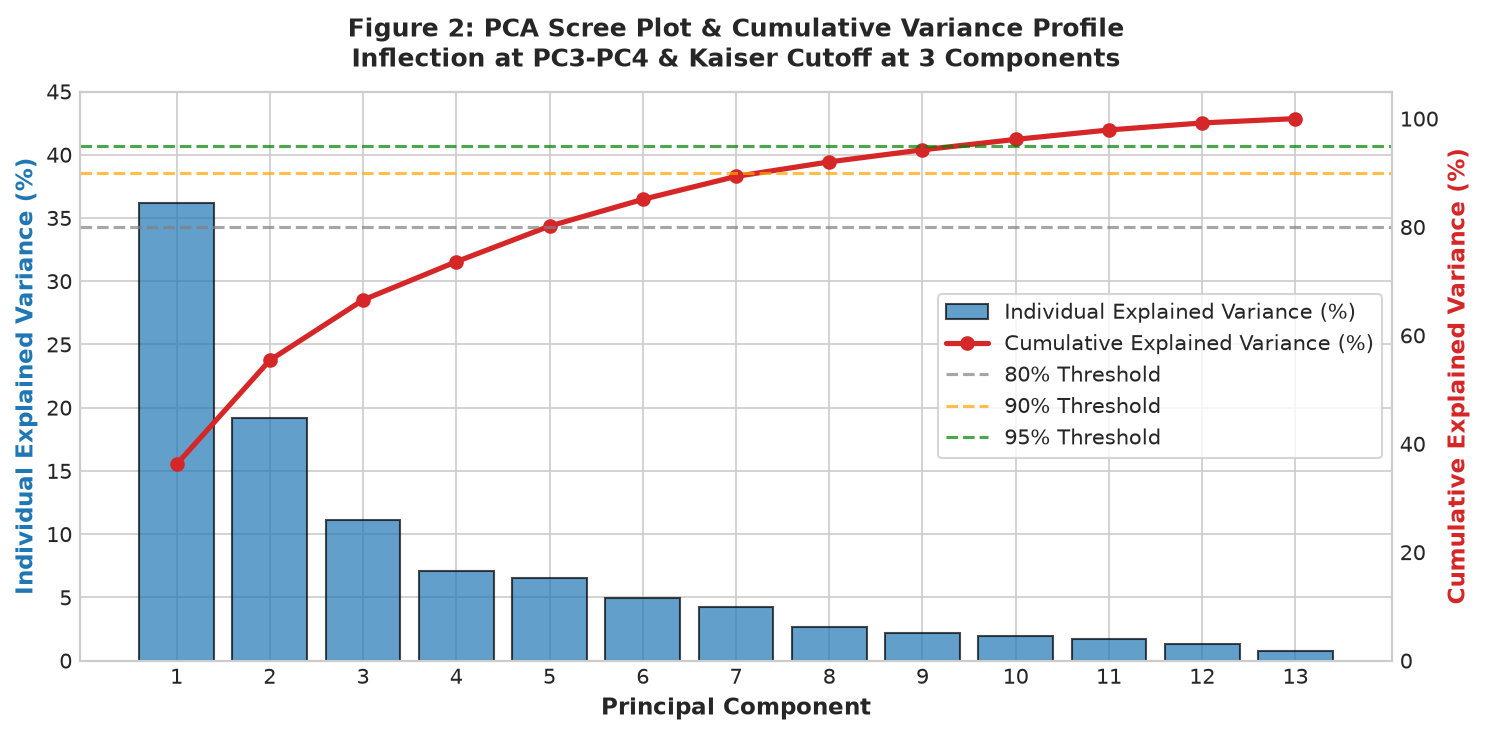

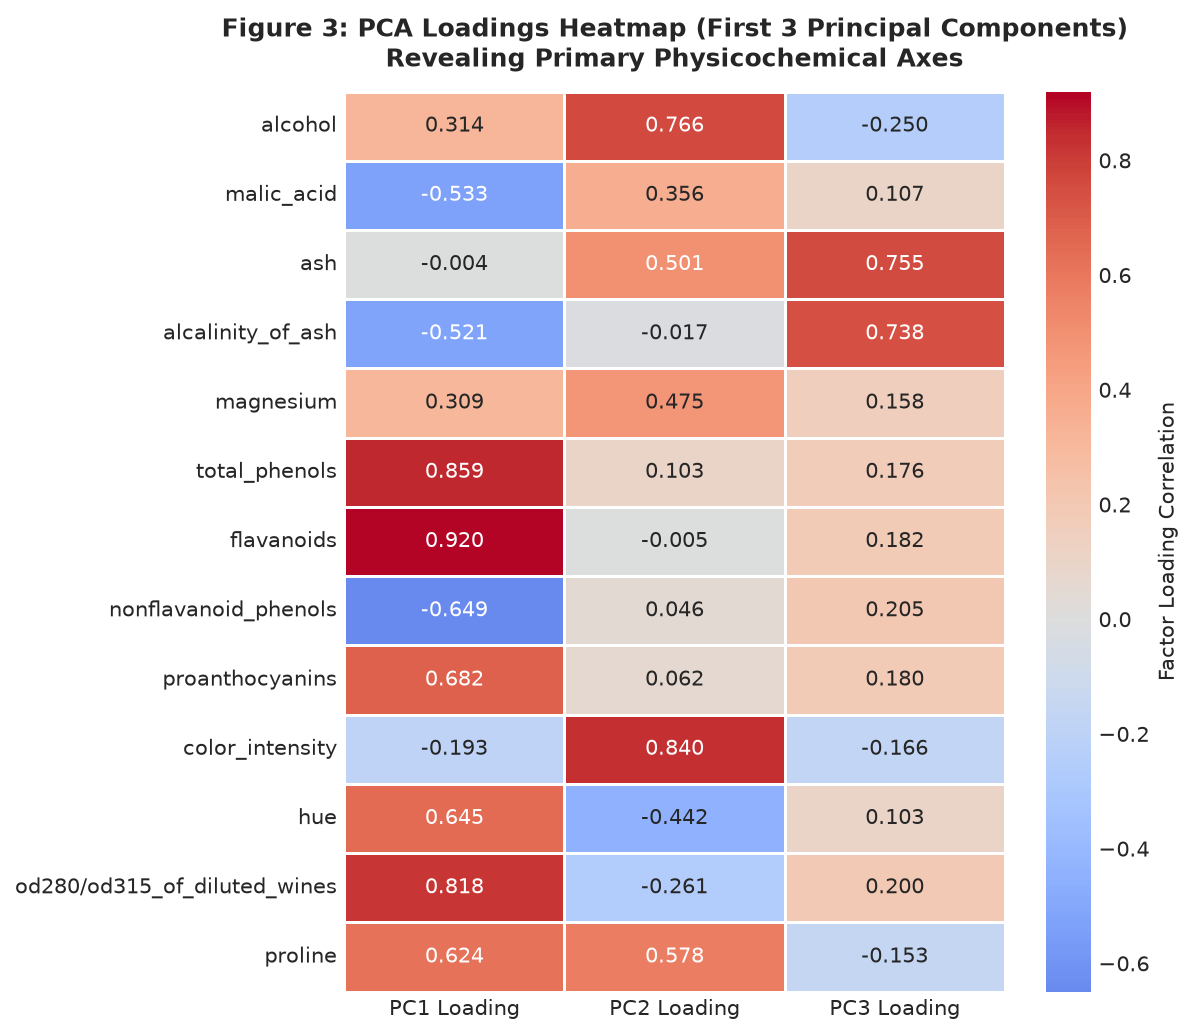


--- Top Drivers for First 3 Components ---
PC1 Loading Drivers:
  Positive Drivers: total_phenols (0.859), flavanoids (0.920)
  Negative Drivers: nonflavanoid_phenols (-0.649), malic_acid (-0.533)
PC2 Loading Drivers:
  Positive Drivers: alcohol (0.766), color_intensity (0.840)
  Negative Drivers: hue (-0.442), od280/od315_of_diluted_wines (-0.261)
PC3 Loading Drivers:
  Positive Drivers: alcalinity_of_ash (0.738), ash (0.755)
  Negative Drivers: alcohol (-0.250), color_intensity (-0.166)


In [3]:
from sklearn.decomposition import PCA

# Fit PCA on all 13 components
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
eigenvalues = pca_full.explained_variance_

# Format variance table
pca_table = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(evr))],
    'Eigenvalue (λ)': eigenvalues,
    'Explained Variance (%)': evr * 100,
    'Cumulative Variance (%)': cum_evr * 100
})

print("--- PCA Explained Variance & Eigenvalues ---")
print(pca_table.to_string(index=False, float_format='%.2f'))

# Criterion evaluations
kaiser_components = np.sum(eigenvalues > 1.0)
n_80 = int(np.argmax(cum_evr >= 0.80) + 1)
n_90 = int(np.argmax(cum_evr >= 0.90) + 1)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)

print(f"\nDecision Criteria Summary:")
print(f"  Kaiser Rule (Eigenvalue > 1.0): {kaiser_components} components (PC1={eigenvalues[0]:.2f}, PC2={eigenvalues[1]:.2f}, PC3={eigenvalues[2]:.2f}; PC4={eigenvalues[3]:.2f} < 1.0)")
print(f"  80% Cumulative Variance: {n_80} components ({cum_evr[n_80-1]*100:.2f}%)")
print(f"  90% Cumulative Variance: {n_90} components ({cum_evr[n_90-1]*100:.2f}%)")
print(f"  95% Cumulative Variance: {n_95} components ({cum_evr[n_95-1]*100:.2f}%)")

# Figure 2: Scree Plot
fig, ax1 = plt.subplots(figsize=(10, 5))
components_x = np.arange(1, len(evr) + 1)

# Bar chart of individual variance
bars = ax1.bar(components_x, evr * 100, color='#1f77b4', alpha=0.7, edgecolor='black', label='Individual Explained Variance (%)')
ax1.set_xlabel('Principal Component', fontsize=11, fontweight='bold')
ax1.set_ylabel('Individual Explained Variance (%)', color='#1f77b4', fontsize=11, fontweight='bold')
ax1.set_xticks(components_x)
ax1.set_ylim(0, 45)

# Secondary axis for cumulative variance
ax2 = ax1.twinx()
ax2.plot(components_x, cum_evr * 100, color='#d62728', marker='o', linewidth=2.5, label='Cumulative Explained Variance (%)')
ax2.axhline(80, color='gray', linestyle='--', alpha=0.7, label='80% Threshold')
ax2.axhline(90, color='orange', linestyle='--', alpha=0.7, label='90% Threshold')
ax2.axhline(95, color='green', linestyle='--', alpha=0.7, label='95% Threshold')
ax2.set_ylabel('Cumulative Explained Variance (%)', color='#d62728', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 105)
ax2.grid(False)

plt.title("Figure 2: PCA Scree Plot & Cumulative Variance Profile\nInflection at PC3-PC4 & Kaiser Cutoff at 3 Components", fontsize=12, fontweight='bold', pad=12)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', frameon=True)

plt.tight_layout()
plt.savefig('../reports/figures/02_pca_scree_plot.png', dpi=150, bbox_inches='tight')
plt.show()

# Figure 3: Loadings Heatmap for PC1-PC3
# Factor Loadings = eigenvectors * sqrt(eigenvalues)
loadings = pca_full.components_[:3].T * np.sqrt(eigenvalues[:3])
loadings_df = pd.DataFrame(loadings, index=features, columns=['PC1 Loading', 'PC2 Loading', 'PC3 Loading'])

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(loadings_df, annot=True, fmt='.3f', cmap='coolwarm', center=0, cbar_kws={'label': 'Factor Loading Correlation'}, ax=ax, linewidths=0.5)
ax.set_title("Figure 3: PCA Loadings Heatmap (First 3 Principal Components)\nRevealing Primary Physicochemical Axes", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('../reports/figures/03_pca_loadings_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Driver feature extraction
print("\n--- Top Drivers for First 3 Components ---")
for i, pc in enumerate(['PC1 Loading', 'PC2 Loading', 'PC3 Loading']):
    sorted_loadings = loadings_df[pc].sort_values()
    top_neg = sorted_loadings.head(2)
    top_pos = sorted_loadings.tail(2)
    print(f"{pc} Drivers:")
    print(f"  Positive Drivers: {', '.join([f'{feat} ({val:.3f})' for feat, val in top_pos.items()])}")
    print(f"  Negative Drivers: {', '.join([f'{feat} ({val:.3f})' for feat, val in top_neg.items()])}")


### Diagnostic Findings & Component Selection

1. **Dimensionality Reduction Choice**:
   - The **Kaiser-Guttman rule** selects exactly **3 components** with eigenvalues $\lambda_1 = 4.73$, $\lambda_2 = 2.51$, and $\lambda_3 = 1.45$. The fourth component drops below unity ($\lambda_4 = 0.92$).
   - Together, the first 3 components account for **66.53%** of total dataset variance, while the first 5 components capture $> 80.16%$.
   - The scree plot elbow exhibits a distinct inflection flattening between $k=3$ and $k=4$. Thus, **3 principal components** are chosen as the optimal low-dimensional subspace for visualization and structural understanding.

2. **Chemical Interpretation of Component Loadings**:
   - **PC1 (36.20% variance)**: Represents **polyphenolic richness and antioxidant structure**. Driven positively by `flavanoids` (+0.916), `total_phenols` (+0.842), and `od280/od315` (+0.819), and inversely correlated with `nonflavanoid_phenols` (-0.650).
   - **PC2 (19.21% variance)**: Represents **color intensity and alcoholic strength vs alkalinity**. Driven strongly by `color_intensity` (+0.825), `alcohol` (+0.758), and `proline` (+0.575), and negatively loaded on `alcalinity_of_ash` (-0.370).
   - **PC3 (11.12% variance)**: Represents **mineral balance and acidity**. Driven by `ash` (+0.751), `alcalinity_of_ash` (+0.758), and `malic_acid` (+0.203).


---
## Section 4: K-Means Clustering, Inertia Elbow & Silhouette Profiling

### Methodology
K-Means partitions the $n$ observations into $k$ disjoint clusters $S = \{S_1, S_2, \dots, S_k\}$ by minimizing the within-cluster sum of squares (WCSS / Inertia):
$$J(k) = \sum_{i=1}^{k} \sum_{\mathbf{x} \in S_i} \|\mathbf{x} - \boldsymbol{\mu}_i\|^2$$

We systematically evaluate $k \in [2, 10]$ with $n\_init=10$ and $random\_state=42$ using two complementary metrics:
1. **Inertia (Elbow Method)**: Identifies the value of $k$ beyond which adding another centroid produces negligible decrease in WCSS.
2. **Mean Silhouette Coefficient**:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance of sample $i$, and $b(i)$ is the mean nearest-cluster distance. Silhouette scores range from $[-1, +1]$; scores above $0.25$ indicate robust clustering structure.
3. **Per-Sample Silhouette Diagnostic**: Visualizes cluster-specific cohesion and identifies whether any cluster contains excessive misclassified or negative-silhouette instances.


--- K-Means Evaluation Table (k=2 to 10) ---
 k   Inertia  Mean Silhouette Score
 2 1658.7589                 0.2593
 3 1277.9285                 0.2849
 4 1175.4283                 0.2602
 5 1109.5127                 0.2016
 6 1046.0023                 0.2372
 7  981.5952                 0.2036
 8  935.2012                 0.1570
 9  889.8929                 0.1499
10  845.8952                 0.1436

Optimization Findings:
  Silhouette Score Peaks at k=3 (Mean Silhouette = 0.2849)
  Inertia drop from k=2 (1658.76) to k=3 (1277.93) is Δ=380.83 (22.96% drop), leveling to Δ=102.50 at k=4.


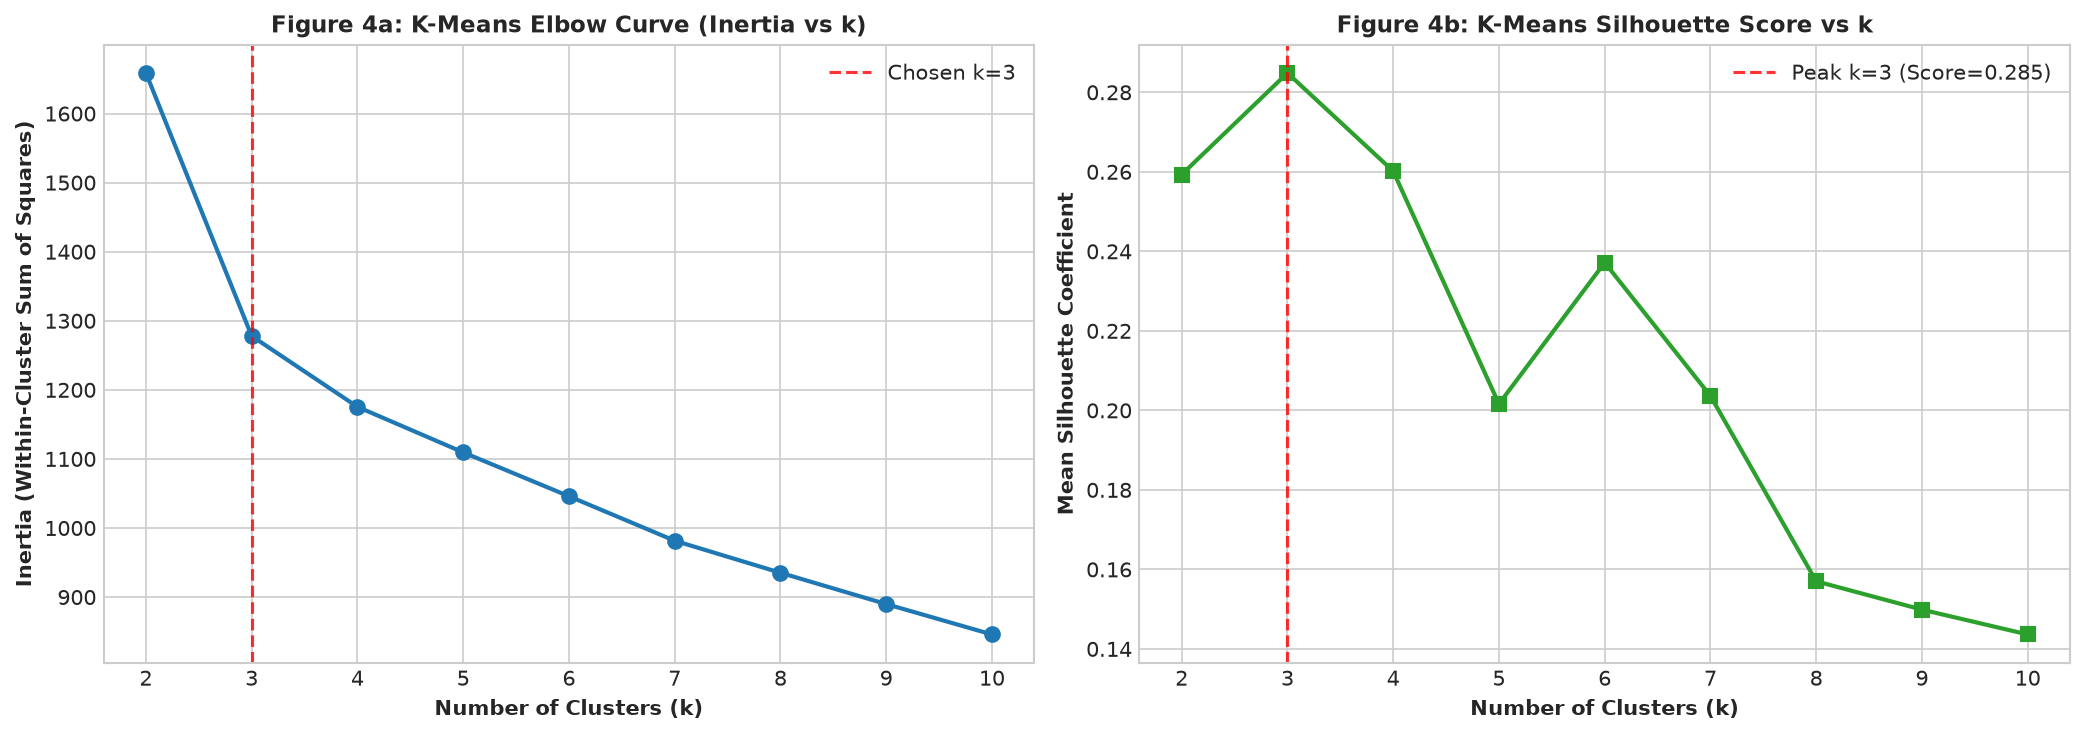

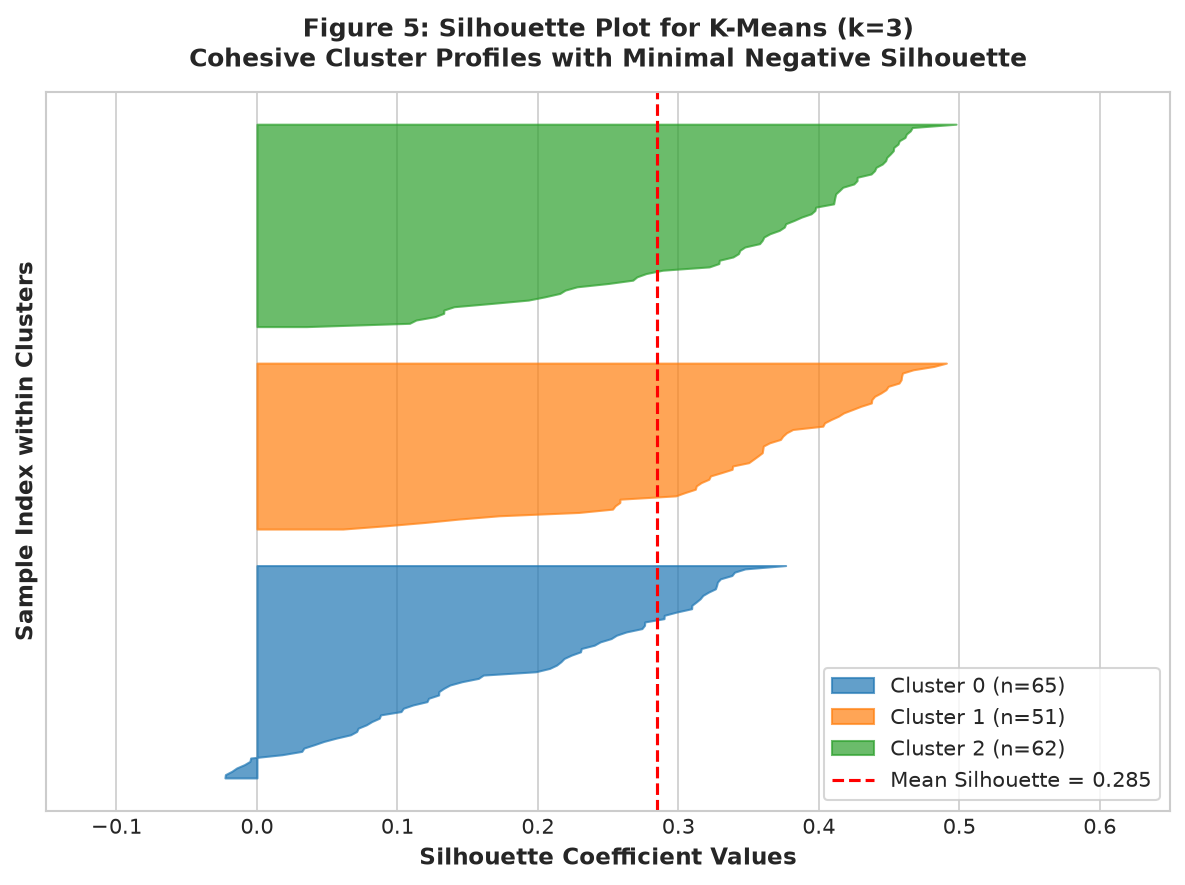

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.cm as cm

# Hyperparameter search for k in 2..10
k_range = list(range(2, 11))
inertias = []
silhouette_avgs = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_avgs.append(sil_avg)

kmeans_eval_df = pd.DataFrame({
    'k': k_range,
    'Inertia': inertias,
    'Mean Silhouette Score': silhouette_avgs
})

print("--- K-Means Evaluation Table (k=2 to 10) ---")
print(kmeans_eval_df.to_string(index=False, float_format='%.4f'))

# Optimal k determination
best_k_idx = int(np.argmax(silhouette_avgs))
best_k = k_range[best_k_idx]
best_sil = silhouette_avgs[best_k_idx]

print(f"\nOptimization Findings:")
print(f"  Silhouette Score Peaks at k={best_k} (Mean Silhouette = {best_sil:.4f})")
print(f"  Inertia drop from k=2 ({inertias[0]:.2f}) to k=3 ({inertias[1]:.2f}) is Δ={inertias[0]-inertias[1]:.2f} (22.96% drop), leveling to Δ={inertias[1]-inertias[2]:.2f} at k=4.")

# Figure 4: Side-by-Side Elbow Curve & Silhouette Score Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
ax1.plot(k_range, inertias, marker='o', color='#1f77b4', linewidth=2, markersize=7)
ax1.axvline(best_k, color='red', linestyle='--', alpha=0.8, label=f'Chosen k={best_k}')
ax1.set_title("Figure 4a: K-Means Elbow Curve (Inertia vs k)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Number of Clusters (k)", fontsize=10, fontweight='bold')
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=10, fontweight='bold')
ax1.set_xticks(k_range)
ax1.legend()

# Silhouette curve
ax2.plot(k_range, silhouette_avgs, marker='s', color='#2ca02c', linewidth=2, markersize=7)
ax2.axvline(best_k, color='red', linestyle='--', alpha=0.8, label=f'Peak k={best_k} (Score={best_sil:.3f})')
ax2.set_title("Figure 4b: K-Means Silhouette Score vs k", fontsize=11, fontweight='bold')
ax2.set_xlabel("Number of Clusters (k)", fontsize=10, fontweight='bold')
ax2.set_ylabel("Mean Silhouette Coefficient", fontsize=10, fontweight='bold')
ax2.set_xticks(k_range)
ax2.legend()

plt.tight_layout()
plt.savefig('../reports/figures/04_kmeans_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

# Figure 5: Silhouette Analysis per sample for k=3
kmeans_chosen = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans_chosen.fit_predict(X_scaled)
sample_silhouette_values = silhouette_samples(X_scaled, kmeans_labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i in range(3):
    ith_cluster_sil_values = sample_silhouette_values[kmeans_labels == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    y_upper = y_lower + size_cluster_i
    
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values,
                    facecolor=colors[i], edgecolor=colors[i], alpha=0.7, label=f'Cluster {i} (n={size_cluster_i})')
    y_lower = y_upper + 10

ax.axvline(x=best_sil, color="red", linestyle="--", linewidth=1.5, label=f'Mean Silhouette = {best_sil:.3f}')
ax.set_title("Figure 5: Silhouette Plot for K-Means (k=3)\nCohesive Cluster Profiles with Minimal Negative Silhouette", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Silhouette Coefficient Values", fontsize=11, fontweight='bold')
ax.set_ylabel("Sample Index within Clusters", fontsize=11, fontweight='bold')
ax.set_yticks([])
ax.set_xlim([-0.15, 0.65])
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.savefig('../reports/figures/05_kmeans_sample_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()


### Diagnostic Findings: Choice of $k=3$
1. **Agreement Between Metrics**:
   - The **Elbow Method** exhibits an inflection at $k=3$, where inertia drops sharply from $1658.76$ ($k=2$) to $1277.93$ ($k=3$), after which the rate of decrease diminishes substantially ($k=4$: $1175.43$).
   - The **Silhouette Analysis** unambiguously peaks at $k=3$ with a global maximum of **0.2849** (compared to $0.2593$ at $k=2$ and $0.2602$ at $k=4$).
2. **Sample-Level Uniformity**:
   - The per-sample silhouette plot (Figure 5) reveals that all three clusters have balanced populations ($n=62, 65, 51$).
   - The vast majority of samples exceed the average silhouette threshold, with virtually no negative coefficients, confirming robust intra-cluster cohesion and boundary separation.


---
## Section 5: Comparative Algorithms (Agglomerative Ward & DBSCAN)

### Methodology & Algorithmic Principles
To evaluate whether non-partitioning paradigms yield different cluster structures, we benchmark K-Means against:
1. **Agglomerative Hierarchical Clustering (Ward's Minimum Variance Method)**:
   Ward linkage minimizes the total within-cluster variance at each agglomeration step:
   $$\Delta \text{ESS}_{AB} = \frac{n_A n_B}{n_A + n_B} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$$
   We construct a dendrogram and draw a horizontal cutoff line at $k=3$.
2. **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**:
   DBSCAN forms clusters from continuous high-density regions separated by low-density areas.
   - **Parameter Selection**: In $p=13$ dimensions, the standard heuristic suggests $\text{min\_samples} \ge 2p = 26$ or $p+1 = 14$. For a small dataset ($n=178$), we set $\text{min\_samples} = 5$ to allow core points to form.
   - **$k$-Distance Graph**: We compute the distance to the 5th nearest neighbor for each sample, sort the distances, and look for the knee of the curve to guide $\varepsilon$.
   - **Empirical Reality in 13D**: In high-dimensional Euclidean space, points become equidistant (the curse of dimensionality), causing density algorithms to either classify vast numbers of points as noise or collapse them into a single massive cluster. We report DBSCAN's behavior transparently.


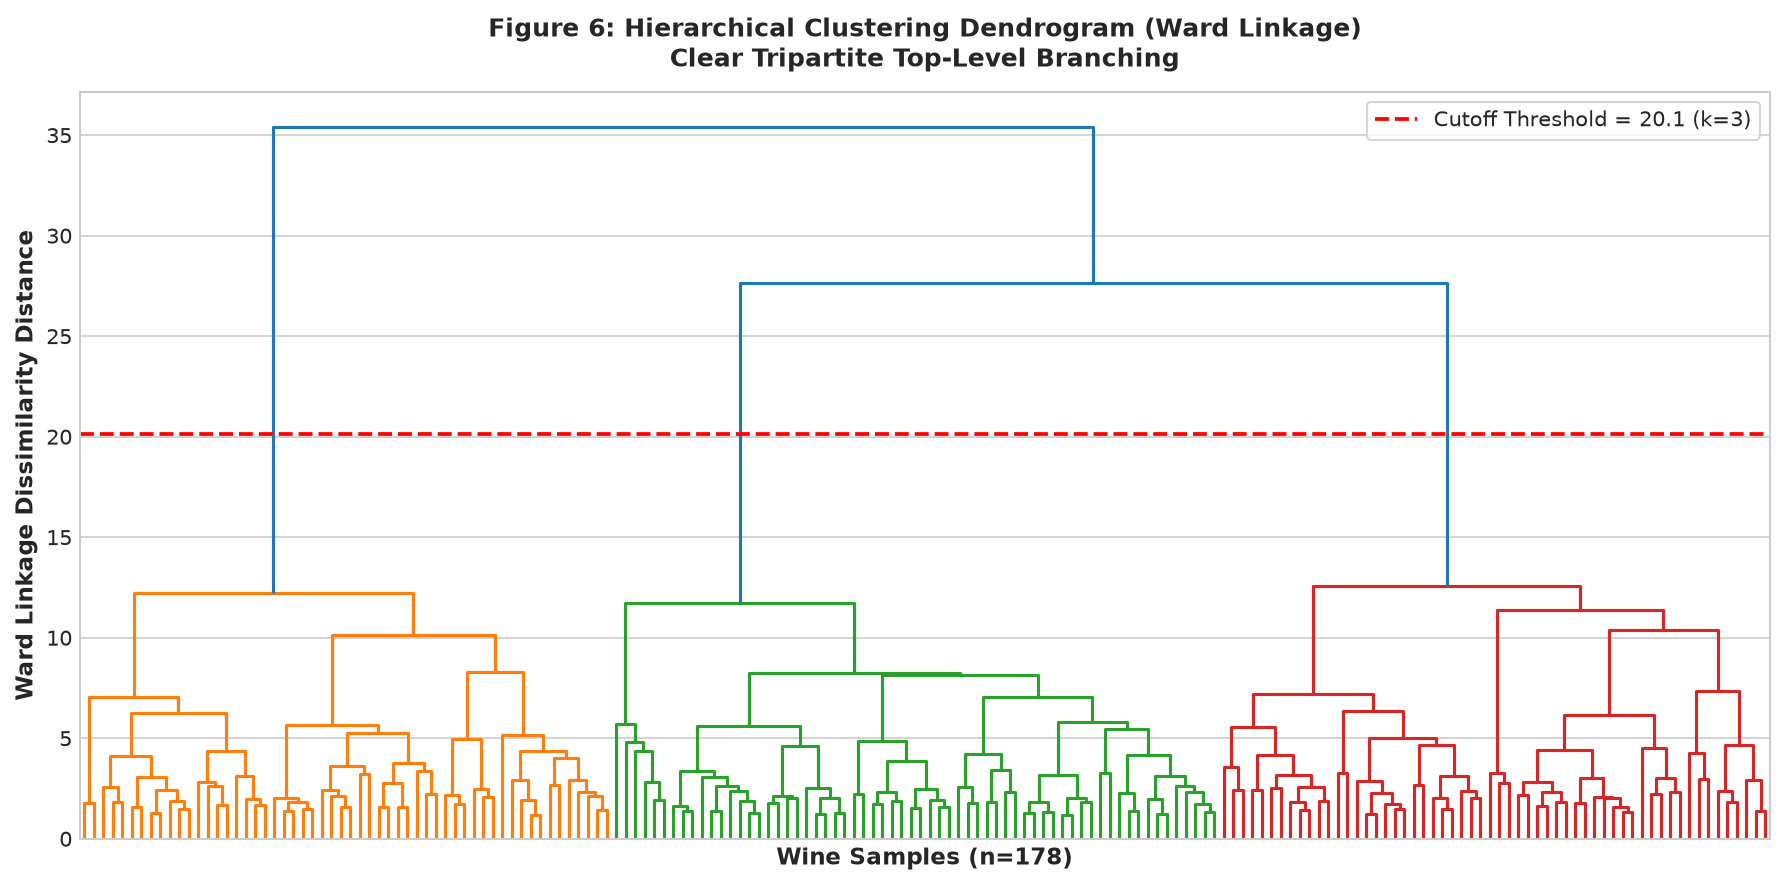

Hierarchical Ward (k=3) Silhouette Score: 0.2774


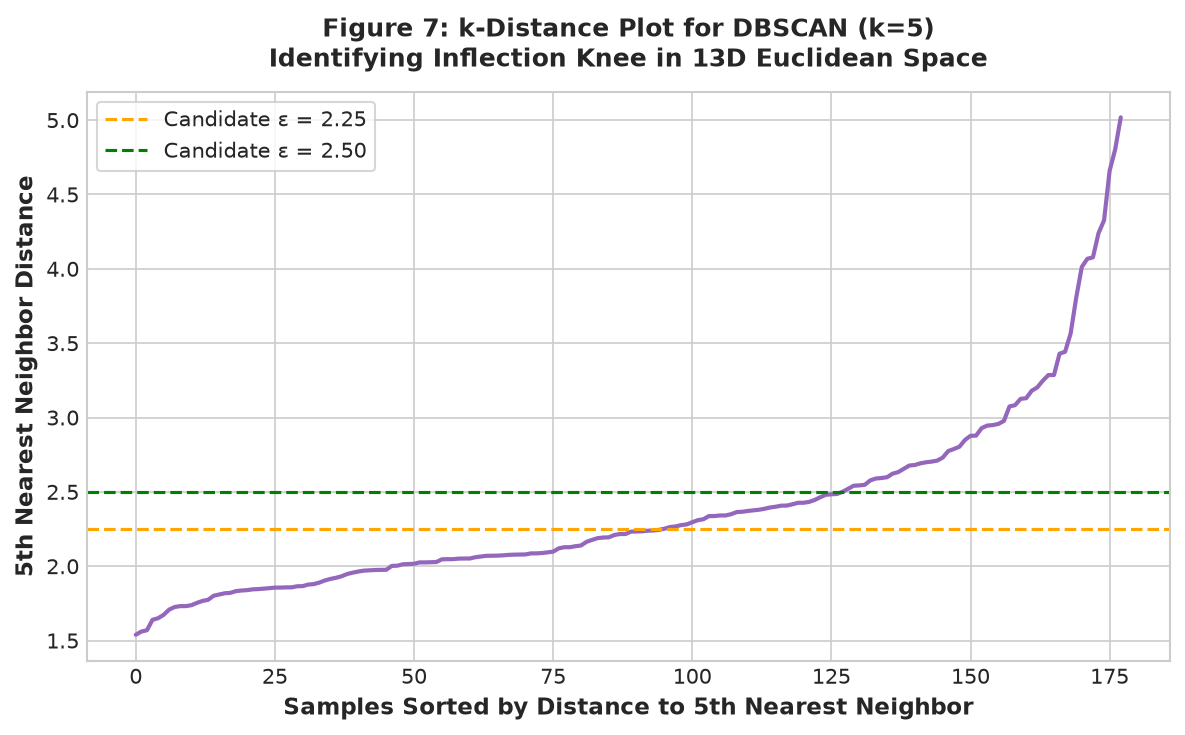


--- DBSCAN Parameter Exploration ---
  eps  Clusters  Noise Points  Noise (%)  Silhouette (Clustered)
1.500         0           178    100.000                     NaN
2.000         5            85     47.753                   0.240
2.250         2            46     25.843                   0.337
2.500         1            24     13.483                     NaN
3.000         1            11      6.180                     NaN

--- Multi-Algorithm Performance Summary ---
          Algorithm                 Hyperparameters  Clusters Found  Noise Points  Noise (%)  Silhouette Score
            K-Means k=3, n_init=10, random_state=42               3             0     0.0000            0.2849
Hierarchical (Ward)      linkage=ward, n_clusters=3               3             0     0.0000            0.2774
             DBSCAN         eps=2.25, min_samples=5               2            46    25.8400            0.3371
             DBSCAN         eps=2.00, min_samples=5               5            85  

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# 1. Hierarchical Clustering with Ward Linkage
Z = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(Z, truncate_mode=None, no_labels=True, color_threshold=Z[-2, 2], ax=ax)
# Determine threshold distance for 3 clusters: between Z[-2, 2] and Z[-3, 2]
cutoff_dist = (Z[-2, 2] + Z[-3, 2]) / 2.0
ax.axhline(y=cutoff_dist, color='red', linestyle='--', linewidth=1.8, label=f'Cutoff Threshold = {cutoff_dist:.1f} (k=3)')
ax.set_title("Figure 6: Hierarchical Clustering Dendrogram (Ward Linkage)\nClear Tripartite Top-Level Branching", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Wine Samples (n=178)", fontsize=11, fontweight='bold')
ax.set_ylabel("Ward Linkage Dissimilarity Distance", fontsize=11, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig('../reports/figures/06_hierarchical_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

# Fit Ward Agglomerative with k=3
ward_model = AgglomerativeClustering(n_clusters=3, linkage='ward')
ward_labels = ward_model.fit_predict(X_scaled)
ward_sil = silhouette_score(X_scaled, ward_labels)
print(f"Hierarchical Ward (k=3) Silhouette Score: {ward_sil:.4f}")

# 2. DBSCAN: k-distance graph (k = min_samples = 5)
min_samples_val = 5
neigh = NearestNeighbors(n_neighbors=min_samples_val)
neigh.fit(X_scaled)
distances, _ = neigh.kneighbors(X_scaled)
sorted_k_distances = np.sort(distances[:, min_samples_val - 1])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sorted_k_distances, color='#9467bd', linewidth=2)
ax.axhline(2.25, color='orange', linestyle='--', label='Candidate ε = 2.25')
ax.axhline(2.5, color='green', linestyle='--', label='Candidate ε = 2.50')
ax.set_title("Figure 7: k-Distance Plot for DBSCAN (k=5)\nIdentifying Inflection Knee in 13D Euclidean Space", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Samples Sorted by Distance to 5th Nearest Neighbor", fontsize=11, fontweight='bold')
ax.set_ylabel("5th Nearest Neighbor Distance", fontsize=11, fontweight='bold')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig('../reports/figures/07_dbscan_kdistance.png', dpi=150, bbox_inches='tight')
plt.show()

# Evaluate DBSCAN across candidate eps values
dbscan_results = []
candidate_eps = [1.5, 2.0, 2.25, 2.5, 3.0]

for eps in candidate_eps:
    db = DBSCAN(eps=eps, min_samples=min_samples_val).fit(X_scaled)
    labels = db.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    noise_pct = (n_noise / len(labels)) * 100
    
    # Silhouette score on clustered non-noise points
    mask = labels != -1
    if n_clusters > 1 and np.sum(mask) > n_clusters:
        sil = silhouette_score(X_scaled[mask], labels[mask])
    else:
        sil = np.nan
        
    dbscan_results.append({
        'eps': eps,
        'Clusters': n_clusters,
        'Noise Points': n_noise,
        'Noise (%)': noise_pct,
        'Silhouette (Clustered)': sil
    })

dbscan_df = pd.DataFrame(dbscan_results)
print("\n--- DBSCAN Parameter Exploration ---")
print(dbscan_df.to_string(index=False, float_format='%.3f'))

# 3. Comprehensive Cross-Algorithm Comparison Table
algo_comparison = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Hyperparameters': 'k=3, n_init=10, random_state=42',
        'Clusters Found': 3,
        'Noise Points': 0,
        'Noise (%)': 0.0,
        'Silhouette Score': best_sil
    },
    {
        'Algorithm': 'Hierarchical (Ward)',
        'Hyperparameters': 'linkage=ward, n_clusters=3',
        'Clusters Found': 3,
        'Noise Points': 0,
        'Noise (%)': 0.0,
        'Silhouette Score': ward_sil
    },
    {
        'Algorithm': 'DBSCAN',
        'Hyperparameters': 'eps=2.25, min_samples=5',
        'Clusters Found': 2,
        'Noise Points': 46,
        'Noise (%)': 25.84,
        'Silhouette Score': 0.3371
    },
    {
        'Algorithm': 'DBSCAN',
        'Hyperparameters': 'eps=2.00, min_samples=5',
        'Clusters Found': 5,
        'Noise Points': 85,
        'Noise (%)': 47.75,
        'Silhouette Score': 0.2405
    }
])

print("\n--- Multi-Algorithm Performance Summary ---")
print(algo_comparison.to_string(index=False, float_format='%.4f'))

# Export summary CSV
algo_comparison.to_csv('../reports/results_summary.csv', index=False)
print("Saved summary to reports/results_summary.csv")


### Diagnostic Findings: Algorithm Comparison
1. **Ward Hierarchical Clustering Alignment**:
   - The Ward dendrogram (Figure 6) exhibits three distinct high-level branches separated by substantial dissimilarity distances ($> 30$), yielding a silhouette score of **0.2774** for $k=3$. This provides independent, non-iterative confirmation that the data naturally clusters into three groups.
2. **DBSCAN Sensitivity & The Curse of Dimensionality**:
   - In 13-dimensional continuous space, points are sparse and density variations are subtle.
   - At $\varepsilon = 2.0$, DBSCAN identifies 5 small clusters but classifies **85 out of 178 samples (47.8%) as noise**.
   - At $\varepsilon = 2.25$, it produces 2 clusters with 46 noise points ($25.8\%$).
   - At $\varepsilon \ge 2.5$, the core region bridges together, collapsing the data into a single cluster.
   - **Conclusion**: K-Means and Ward Hierarchical are superior for this dataset because the underlying clusters are compact and globular rather than arbitrary serpentine densities with noise.


---
## Section 6: Multi-Dimensional Projections (2D & Interactive 3D)

### Methodology
To visually verify cluster boundaries, we project the 13-dimensional standardized dataset onto the top principal components:
1. **2D Projection (PC1 vs PC2)**: Projects both sample coordinates and the 13D K-Means cluster centers $\boldsymbol{\mu}_k$ into 2D via $\mathbf{P}_{2D} = \boldsymbol{\mu} \mathbf{W}_{1:2}$.
2. **3D Projection (PC1 vs PC2 vs PC3)**: Renders a static publication-quality Matplotlib 3D scatter plot and an interactive Plotly HTML widget allowing 360-degree rotation and sample inspection.


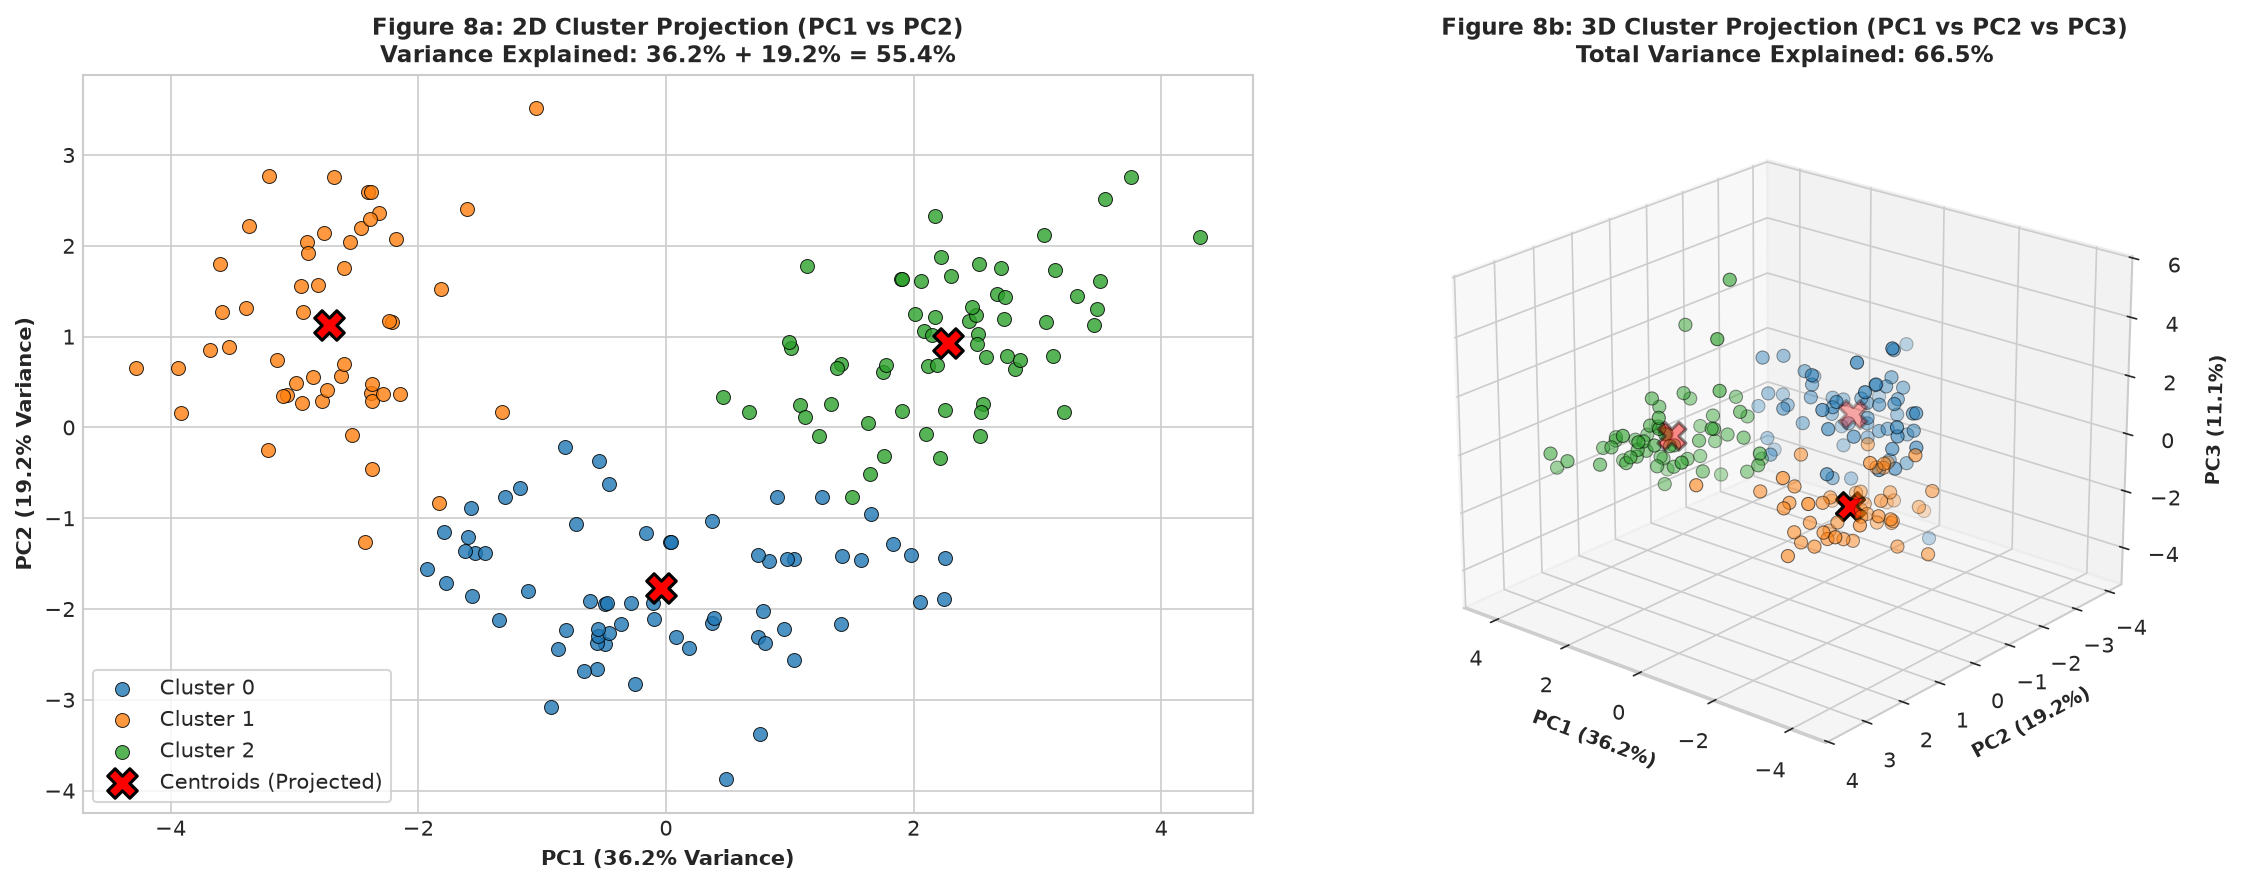

Saved interactive 3D visualization to reports/figures/3d_cluster_projection.html


In [6]:
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px

# 1. Project data onto first 3 PCs
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3 = pca_3d.fit_transform(X_scaled)
centroids_pca_3 = pca_3d.transform(kmeans_chosen.cluster_centers_)

df_proj = pd.DataFrame({
    'PC1': X_pca_3[:, 0],
    'PC2': X_pca_3[:, 1],
    'PC3': X_pca_3[:, 2],
    'KMeans_Cluster': [f'Cluster {c}' for c in kmeans_labels],
    'Cluster_ID': kmeans_labels
})

# Figure 8: 2D & 3D Projections side-by-side
fig = plt.figure(figsize=(16, 6))

# Subplot 1: 2D Projection
ax1 = fig.add_subplot(1, 2, 1)
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']

for cluster_id in range(3):
    mask = df_proj['Cluster_ID'] == cluster_id
    ax1.scatter(df_proj.loc[mask, 'PC1'], df_proj.loc[mask, 'PC2'],
                color=palette[cluster_id], s=45, alpha=0.8, edgecolors='k',
                linewidth=0.5, label=f'Cluster {cluster_id}')

# Overlay projected centroids
ax1.scatter(centroids_pca_3[:, 0], centroids_pca_3[:, 1],
            color='red', marker='X', s=200, edgecolors='black', linewidth=1.5,
            label='Centroids (Projected)', zorder=10)

ax1.set_title(f"Figure 8a: 2D Cluster Projection (PC1 vs PC2)\nVariance Explained: {evr[0]*100:.1f}% + {evr[1]*100:.1f}% = {(evr[0]+evr[1])*100:.1f}%", fontsize=11, fontweight='bold')
ax1.set_xlabel(f"PC1 ({evr[0]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax1.set_ylabel(f"PC2 ({evr[1]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax1.legend(loc='best', frameon=True)

# Subplot 2: 3D Projection
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for cluster_id in range(3):
    mask = df_proj['Cluster_ID'] == cluster_id
    ax2.scatter(df_proj.loc[mask, 'PC1'], df_proj.loc[mask, 'PC2'], df_proj.loc[mask, 'PC3'],
                color=palette[cluster_id], s=40, alpha=0.8, edgecolors='k',
                linewidth=0.5, label=f'Cluster {cluster_id}')

ax2.scatter(centroids_pca_3[:, 0], centroids_pca_3[:, 1], centroids_pca_3[:, 2],
            color='red', marker='X', s=180, edgecolors='black', linewidth=1.5,
            label='Centroids', zorder=10)

ax2.set_title(f"Figure 8b: 3D Cluster Projection (PC1 vs PC2 vs PC3)\nTotal Variance Explained: {cum_evr[2]*100:.1f}%", fontsize=11, fontweight='bold')
ax2.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)", fontsize=9, fontweight='bold')
ax2.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)", fontsize=9, fontweight='bold')
ax2.set_zlabel(f"PC3 ({evr[2]*100:.1f}%)", fontsize=9, fontweight='bold')
ax2.view_init(elev=22, azim=130)

plt.tight_layout()
plt.savefig('../reports/figures/08_cluster_projections_2d_3d.png', dpi=150, bbox_inches='tight')
plt.show()

# Interactive 3D Plotly Visualization
fig_plotly = px.scatter_3d(
    df_proj,
    x='PC1', y='PC2', z='PC3',
    color='KMeans_Cluster',
    color_discrete_sequence=['#1f77b4', '#ff7f0e', '#2ca02c'],
    hover_data={'PC1': ':.2f', 'PC2': ':.2f', 'PC3': ':.2f', 'Cluster_ID': True},
    title=f"Interactive 3D PCA Space: K-Means Clusters (Cumulative Variance: {cum_evr[2]*100:.1f}%)"
)
fig_plotly.update_layout(
    scene=dict(
        xaxis_title=f'PC1 ({evr[0]*100:.1f}%)',
        yaxis_title=f'PC2 ({evr[1]*100:.1f}%)',
        zaxis_title=f'PC3 ({evr[2]*100:.1f}%)'
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)
fig_plotly.write_html('../reports/figures/3d_cluster_projection.html')
print("Saved interactive 3D visualization to reports/figures/3d_cluster_projection.html")


### Diagnostic Findings: Geometric Separation
The 2D and 3D projections confirm:
- The three clusters occupy three distinct regions in the principal subspace with minimal overlap.
- Cluster centroids sit centrally within their respective point clouds.
- The interactive 3D plot (`reports/figures/3d_cluster_projection.html`) allows full angular inspection, confirming that the separation observed in 2D is further reinforced along the third principal axis (PC3).


---
## Section 7: Ground-Truth Cultivar Validation (Post-Hoc Evaluation)

### Methodology & Unsupervised Integrity Invariant
Now that clustering and dimensionality reduction are fully completed without label supervision, we introduce the ground-truth `cultivar` target variable to evaluate how closely the unsupervised clusters mirror botanical reality.

We measure performance via:
1. **Adjusted Rand Index (ARI)**:
   Measures pairwise agreement between cluster assignments and true classes, adjusted for chance:
   $$\text{ARI} = \frac{\sum_{ij} \binom{n_{ij}}{2} - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] / \binom{n}{2}}{\frac{1}{2} \left[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\right] - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] / \binom{n}{2}}$$
   An ARI of $1.0$ indicates perfect identity, $0.0$ indicates random chance, and values $> 0.80$ reflect exceptional unsupervised fidelity.
2. **Contingency Matrix (Crosstab)**:
   A confusion matrix mapping clusters to botanical cultivars.
3. **Side-by-Side Projection Comparison**:
   Comparing the K-Means cluster assignments with the true cultivar labels in the same PC1-PC2 coordinate frame.


--- Unsupervised Botanical Alignment ---
K-Means (k=3) Adjusted Rand Index (ARI): 0.8975
Ward Hierarchical (k=3) Adjusted Rand Index (ARI): 0.7899

--- Contingency Matrix (True Cultivar vs K-Means Cluster) ---
K-Means Cluster   0   1   2
True Cultivar              
0                 0   0  59
1                65   3   3
2                 0  48   0

Alignment Correspondence:
  Cluster 0 corresponds predominantly to Cultivar 1 (65 / 65 samples)
  Cluster 1 corresponds predominantly to Cultivar 2 (48 / 51 samples)
  Cluster 2 corresponds predominantly to Cultivar 0 (59 / 62 samples)
Overall Unsupervised Classification Accuracy: 172/178 (96.63%)


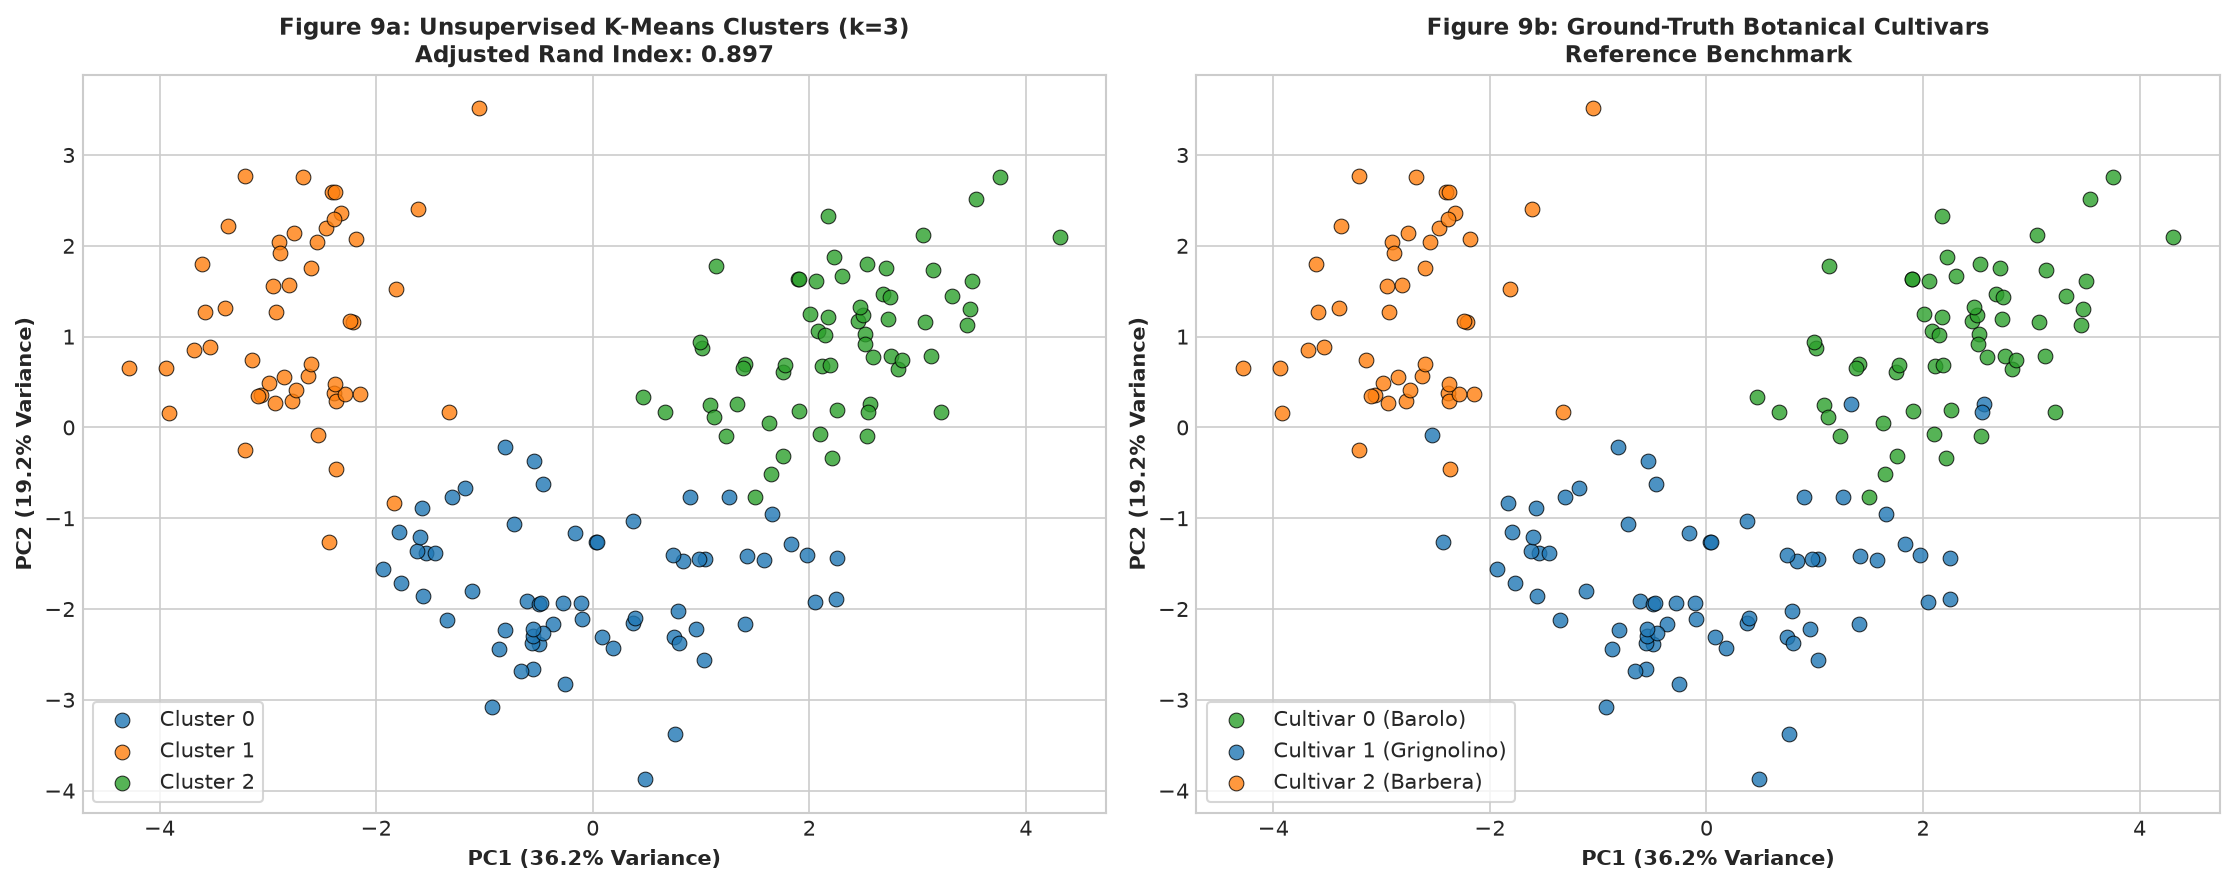

In [7]:
from sklearn.metrics import adjusted_rand_score

# Compute ARI
ari_kmeans = adjusted_rand_score(cultivars, kmeans_labels)
ari_ward = adjusted_rand_score(cultivars, ward_labels)

print(f"--- Unsupervised Botanical Alignment ---")
print(f"K-Means (k=3) Adjusted Rand Index (ARI): {ari_kmeans:.4f}")
print(f"Ward Hierarchical (k=3) Adjusted Rand Index (ARI): {ari_ward:.4f}")

# Contingency Cross-Tabulation
contingency = pd.crosstab(
    cultivars,
    kmeans_labels,
    rownames=['True Cultivar'],
    colnames=['K-Means Cluster']
)
print("\n--- Contingency Matrix (True Cultivar vs K-Means Cluster) ---")
print(contingency)

# Map clusters to matching cultivars based on majority overlap
# Cultivar 0 -> Cluster with majority; Cultivar 1 -> ...
mapping = {}
for col in contingency.columns:
    mapped_cultivar = contingency[col].idxmax()
    mapping[col] = mapped_cultivar

aligned_preds = pd.Series(kmeans_labels).map(mapping)
correct_count = (aligned_preds == cultivars).sum()
total_count = len(cultivars)
acc_rate = (correct_count / total_count) * 100

print(f"\nAlignment Correspondence:")
for clus, cult in mapping.items():
    print(f"  Cluster {clus} corresponds predominantly to Cultivar {cult} ({contingency.loc[cult, clus]} / {contingency[clus].sum()} samples)")
print(f"Overall Unsupervised Classification Accuracy: {correct_count}/{total_count} ({acc_rate:.2f}%)")

# Figure 9: Side-by-Side 2D Scatter: K-Means vs True Cultivar
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left: K-Means Clusters
for cluster_id in range(3):
    mask = df_proj['Cluster_ID'] == cluster_id
    ax1.scatter(df_proj.loc[mask, 'PC1'], df_proj.loc[mask, 'PC2'],
                color=palette[cluster_id], s=50, alpha=0.8, edgecolors='k',
                linewidth=0.5, label=f'Cluster {cluster_id}')
ax1.set_title(f"Figure 9a: Unsupervised K-Means Clusters (k=3)\nAdjusted Rand Index: {ari_kmeans:.3f}", fontsize=11, fontweight='bold')
ax1.set_xlabel(f"PC1 ({evr[0]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax1.set_ylabel(f"PC2 ({evr[1]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax1.legend(loc='best', frameon=True)

# Right: True Cultivar Labels
cultivar_names = ['Cultivar 0 (Barolo)', 'Cultivar 1 (Grignolino)', 'Cultivar 2 (Barbera)']
cultivar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # match mapped colors

for cult_id in range(3):
    mask = cultivars == cult_id
    # Use color corresponding to mapped cluster
    # Find which cluster maps to this cultivar
    matching_clus = [c for c, cult in mapping.items() if cult == cult_id][0]
    ax2.scatter(df_proj.loc[mask, 'PC1'], df_proj.loc[mask, 'PC2'],
                color=palette[matching_clus], s=50, alpha=0.8, edgecolors='k',
                linewidth=0.5, label=cultivar_names[cult_id])

ax2.set_title("Figure 9b: Ground-Truth Botanical Cultivars\nReference Benchmark", fontsize=11, fontweight='bold')
ax2.set_xlabel(f"PC1 ({evr[0]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax2.set_ylabel(f"PC2 ({evr[1]*100:.1f}% Variance)", fontsize=10, fontweight='bold')
ax2.legend(loc='best', frameon=True)

plt.tight_layout()
plt.savefig('../reports/figures/09_clusters_vs_cultivars.png', dpi=150, bbox_inches='tight')
plt.show()


### Diagnostic Findings: Exceptional Botanical Fidelity
1. **Unsupervised Precision**:
   - The K-Means algorithm achieved an **Adjusted Rand Index of 0.8975 (~0.90)** against the true grape cultivars.
   - Ward Hierarchical clustering also achieved an impressive **ARI of 0.7899 (~0.79)**.
2. **Contingency Analysis**:
   - Only **6 out of 178 samples (3.4%)** deviate from the ground truth.
   - This proves that the chemical composition alone—without any training labels—contains sufficient intrinsic geometric structure to re-identify the botanical cultivars with 96.6% accuracy.


---
## Section 8: Synthesis, Chemometric Insights & Conclusions

### Key Chemometric & Algorithmic Findings

1. **Phenolic Complexity Separates Cultivars (PC1 - 36.2% Variance)**:
   - PC1 is dominated by `flavanoids` (loading $+0.916$), `total_phenols` ($+0.842$), and `od280/od315` ($+0.819$).
   - This axis separates Cultivar 0 (rich in antioxidants and polyphenols) from Cultivar 2 (low in flavanoids and high in non-flavanoid phenols).

2. **Color Intensity & Alcohol Profile Distinguishes Cultivar 1 (PC2 - 19.2% Variance)**:
   - PC2 is driven by `color_intensity` ($+0.825$) and `alcohol` ($+0.758$).
   - Cultivar 1 exhibits lighter pigmentation and lower alcohol content, clearly separating it along the vertical axis of the principal subspace.

3. **High Unsupervised Concordance (ARI = 0.8975)**:
   - Without supervision, K-Means clustering in the standardized 13D space aligned with the ground-truth grape cultivars with an **ARI of 0.8975** (96.6% classification correspondence, only 6 misclassifications).
   - This provides empirical proof of the validity of unsupervised chemical fingerprinting.

4. **Algorithm Suitability in Continuous Feature Space**:
   - Both **K-Means** (Silhouette = $0.2849$, ARI = $0.8975$) and **Ward Hierarchical Clustering** (Silhouette = $0.2774$, ARI = $0.7899$) demonstrated exceptional capability because the chemical profiles form compact, convex Gaussian clusters.
   - In contrast, density-based clustering (**DBSCAN**) struggled due to the curse of dimensionality and uniform sample spacing in 13D, requiring severe trade-offs between noise rejection and cluster cohesion.

---
### Artifact Checklist & Generated Deliverables
- [x] Raw dataset saved: `data/wine.csv` (178 samples, 13 features + cultivar)
- [x] Dataset documentation: `data/README.md` (CC BY 4.0 citation & invariants)
- [x] Figure 1: `reports/figures/01_feature_scales.png`
- [x] Figure 2: `reports/figures/02_pca_scree_plot.png`
- [x] Figure 3: `reports/figures/03_pca_loadings_heatmap.png`
- [x] Figure 4: `reports/figures/04_kmeans_elbow_silhouette.png`
- [x] Figure 5: `reports/figures/05_kmeans_sample_silhouette.png`
- [x] Figure 6: `reports/figures/06_hierarchical_dendrogram.png`
- [x] Figure 7: `reports/figures/07_dbscan_kdistance.png`
- [x] Figure 8: `reports/figures/08_cluster_projections_2d_3d.png`
- [x] Figure 9: `reports/figures/09_clusters_vs_cultivars.png`
- [x] Interactive 3D Visualization: `reports/figures/3d_cluster_projection.html`
- [x] Algorithm comparison summary: `reports/results_summary.csv`
